Dataset Shape: (569, 30)
Number of Features: 30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.6676 - loss: 0.6240 - val_accuracy: 0.7033 - val_loss: 0.5213
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8242 - loss: 0.4455 - val_accuracy: 0.8681 - val_loss: 0.3963
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9011 - loss: 0.3531 - val_accuracy: 0.9341 - val_loss: 0.3207
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9231 - loss: 0.2895 - val_accuracy: 0.9231 - val_loss: 0.2688
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9313 - loss: 0.2411 - val_accuracy: 0.9341 - val_loss: 0.2335
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9423 - loss: 0.2043 - val_accuracy: 0.9231 - val_loss: 0.2059
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9505 - loss: 0.1739 - val_accuracy: 0.9341 - val_loss: 0.1876
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9533 - loss: 0.1507 - val_accuracy: 0.9341 - val_loss

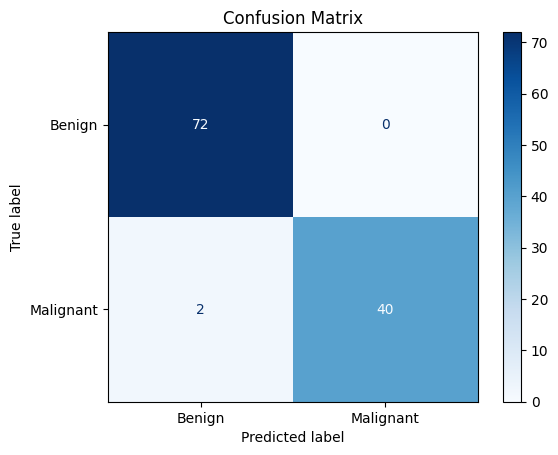

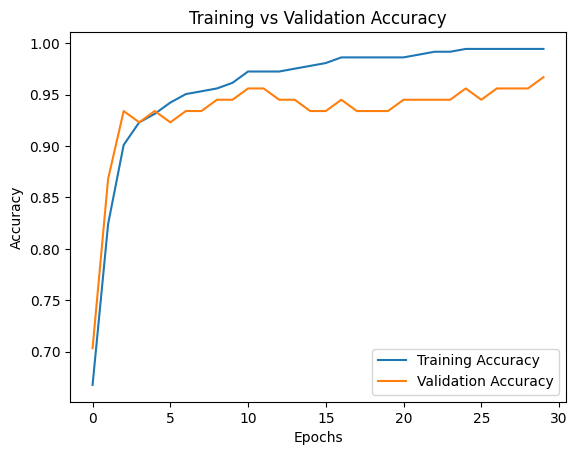

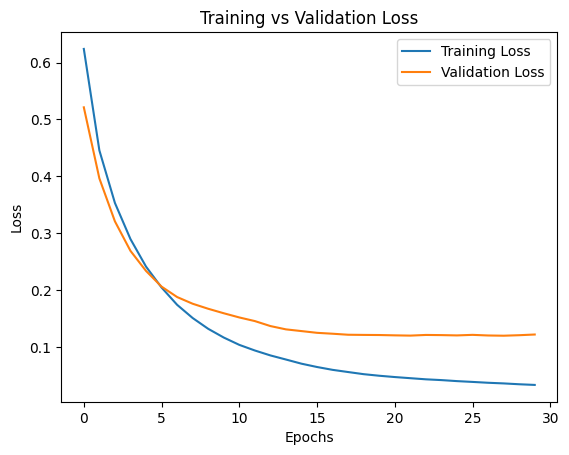

In [1]:

# LAB 6: IMPLEMENTATION OF MLP USING ANN

# 1. Import Libraries
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 2. Load Dataset
data = load_breast_cancer()

X = data.data
y = 1 - data.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Build MLP Model
model = Sequential()

model.add(Dense(16, input_dim=30, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

# 6. Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 7. Display Model Summary
model.summary()

# 8. Train Model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# 9. Model Prediction
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int).flatten()

# 10. Model Evaluation
print("\nModel Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign', 'Malignant']
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

# 12. Training and Validation Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# 13. Training and Validation Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [3]:
#Experimnet 1 (relu in both layers)
model = Sequential()

model.add(Dense(16, input_dim=30, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history1 = model.fit(X_train, y_train,
                     epochs=30,
                     batch_size=16,
                     validation_split=0.2,
                     verbose=0)

loss1, acc1 = model.evaluate(X_test, y_test, verbose=0)

print("ReLU Accuracy:", acc1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ReLU Accuracy: 0.9736841917037964


In [4]:
#Experiment2 (tanh in both layers)
model2 = Sequential()

model2.add(Dense(16, input_dim=30, activation='tanh'))
model2.add(Dense(8, activation='tanh'))
model2.add(Dense(1, activation='sigmoid'))

model2.compile(optimizer='adam',
               loss='binary_crossentropy',
               metrics=['accuracy'])

history2 = model2.fit(X_train, y_train,
                      epochs=30,
                      batch_size=16,
                      validation_split=0.2,
                      verbose=0)

loss2, acc2 = model2.evaluate(X_test, y_test, verbose=0)

print("Tanh Accuracy:", acc2)

Tanh Accuracy: 0.9824561476707458


The Tanh activation function achieved slightly higher accuracy than ReLU for this experiment. Therefore, Tanh performed better under the selected architecture and training conditions.